# Olist E-commerce Data Analysis

## Project Overview
ブラジルのECサイトOlistの公開データを使用し、
SQLとPythonで売上傾向・カテゴリ・地域・リピート顧客を分析する。

## Analysis Questions
- 月ごとの売上はどのように推移しているか
- どの商品カテゴリが売上に貢献しているか
- どの州の売上が高いか
- リピート顧客は売上にどの程度貢献しているか

## Tools
- Python
- pandas
- SQLite / SQL
- matplotlib

1. Project Overview

In [44]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

In [45]:
orders = pd.read_csv('/content/olist_orders_dataset.csv')

In [46]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [47]:
categories = pd.read_csv('/content/product_category_name_translation.csv')
categories.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [48]:
products = pd.read_csv('/content/olist_products_dataset.csv')

In [49]:
customers = pd.read_csv('/content/olist_customers_dataset.csv')

In [50]:
items = pd.read_csv('/content/olist_order_items_dataset.csv')

In [51]:
conn = sqlite3.connect('olist.db')

In [52]:
items.to_sql('order_items',conn, if_exists='replace',index=False)

112650

In [53]:
customers.to_sql('customers', conn, if_exists='replace', index=False)

99441

In [54]:
products.to_sql('products',conn, if_exists='replace', index=False)

32951

In [55]:
categories.to_sql( "categories", conn,if_exists="replace", index=False)

71

In [56]:
orders.to_sql('orders',conn, if_exists='replace',index=False)

99441

In [57]:
query = """
SELECT *
FROM orders
LIMIT 5;
"""
pd.read_sql_query(query, conn)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [58]:
query = """
SELECT order_status, count(*)
FROM orders
GROUP BY order_status;
"""
pd.read_sql_query(query, conn)

,order_status,count(*)
0,approved,2
1,canceled,625
2,created,5
3,delivered,96478
4,invoiced,314
5,processing,301
6,shipped,1107
7,unavailable,609


In [59]:
query = """
SELECT strftime('%Y-%m', order_purchase_timestamp) AS month,
count(*) AS order_count
FROM orders
GROUP BY month;
"""
pd.read_sql_query(query, conn)

,month,order_count
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


In [60]:
query = """
SELECT *
FROM orders AS o
JOIN order_items AS i
    on o.order_id = i.order_id
LIMIT 5;
"""
pd.read_sql_query(query, conn)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,e481f51cbdc54678b7cc49136f2d6af7,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,53cdb2fc8bc7dce0b6741e2150273451,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,47770eb9100c2d0c44946d9cf07ec65d,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,949d5b44dbf5de918fe9c16f97b45f8a,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,ad21c59c0840e6cb83a9ceb5573f8159,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


## 2. Monthly Sales Analysis

In [61]:
query = """
SELECT
    strftime('%Y-%m', o.order_purchase_timestamp) AS month,
    sum(i.price) AS revenue
FROM orders AS o
JOIN order_items AS i
    on o.order_id = i.order_id
GROUP BY month;
"""
pd.read_sql_query(query, conn)

,month,revenue
0,2016-09,267.36
1,2016-10,49507.66
2,2016-12,10.90
3,2017-01,120312.87
4,2017-02,247303.02
5,2017-03,374344.30
6,2017-04,359927.23
7,2017-05,506071.14
8,2017-06,433038.60
9,2017-07,498031.48


In [62]:
query = """
SELECT
    strftime('%Y-%m', o.order_purchase_timestamp) AS month,
    count(DISTINCT o.order_id) AS order_count,
    SUM(i.price) AS revenue
FROM orders AS o
JOIN order_items AS i
    ON o.order_id = i.order_id
GROUP BY month
ORDER BY month;
"""

monthly_sales = pd.read_sql_query(query, conn)
monthly_sales

,month,order_count,revenue
0,2016-09,3,267.36
1,2016-10,308,49507.66
2,2016-12,1,10.90
3,2017-01,789,120312.87
4,2017-02,1733,247303.02
5,2017-03,2641,374344.30
6,2017-04,2391,359927.23
7,2017-05,3660,506071.14
8,2017-06,3217,433038.60
9,2017-07,3969,498031.48


In [63]:
query = """
SELECT
    MIN(order_purchase_timestamp) AS first_order,
    MAX(order_purchase_timestamp) AS last_order
FROM orders
WHERE strftime('%Y-%m', order_purchase_timestamp) = '2016-09'
"""

pd.read_sql_query(query,conn)

,first_order,last_order
0,2016-09-04 21:15:19,2016-09-15 12:16:38


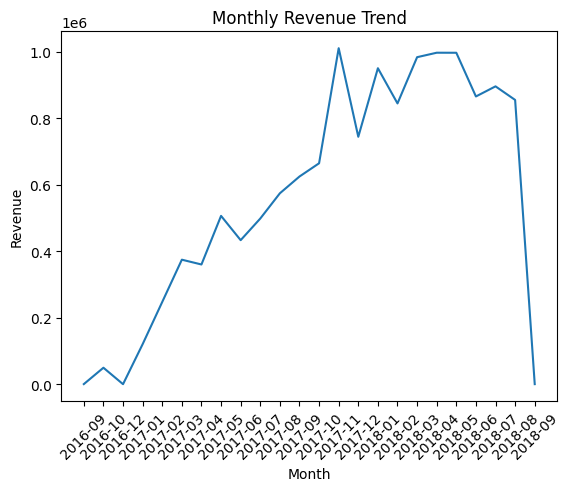

In [64]:
plt.plot(
    monthly_sales["month"],
    monthly_sales["revenue"]
)

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.title("Monthly Revenue Trend")
plt.xticks(rotation=45)
plt.show()



月別の注文数と売上を見ると、2017年から2018年にかけて全体的に増加傾向が見られる。
特に2017年11月は注文数が7,451件、売上が約101万となり、大きく伸びている。

一方、2016年9月や2018年9月などはデータ期間が短いため、他の月との単純な比較には注意が必要である。
全体として、注文数の増加に伴って売上も増加している傾向が確認できる。

3. Category Analysis

In [65]:
query = """
SELECT *
FROM order_items AS i
JOIN products AS p
    ON i.product_id = p.product_id
LIMIT 5;
"""

pd.read_sql_query(query,conn)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,e5f2d52b802189ee658865ca93d83a8f,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,c777355d18b72b67abbeef9df44fd0fd,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,7634da152a4610f1595efa32f14722fc,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ac6c3623068f30de03045865e4e10089,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0


In [66]:
query="""
SELECT
    c.product_category_name_english AS category,
    COUNT(*) AS items_sold,
    SUM(i.price) AS revenue,
    AVG(i.price) AS avg_price
FROM order_items AS i
JOIN products AS p
    ON i.product_id = p.product_id
JOIN categories AS c
    ON p.product_category_name = c.product_category_name
JOIN orders AS o
    ON i.order_id = o.order_id
WHERE o.order_status = 'delivered'
GROUP BY category
ORDER BY revenue DESC;
"""
pd.read_sql_query(query,conn)

,category,items_sold,revenue,avg_price
0,health_beauty,9465,1233131.72,130.283330
1,watches_gifts,5859,1166176.98,199.040276
2,bed_bath_table,10953,1023434.76,93.438762
3,sports_leisure,8431,954852.55,113.254958
4,computers_accessories,7644,888724.61,116.264339
...,...,...,...,...
66,flowers,33,1110.04,33.637576
67,home_comfort_2,30,760.27,25.342333
68,cds_dvds_musicals,14,730.00,52.142857
69,fashion_childrens_clothes,7,519.95,74.278571


In [67]:
category_sales = pd.read_sql_query(query, conn)
top10 = category_sales.head(10)

In [68]:
category_sales.head(10)

,category,items_sold,revenue,avg_price
0,health_beauty,9465,1233131.72,130.283330
1,watches_gifts,5859,1166176.98,199.040276
2,bed_bath_table,10953,1023434.76,93.438762
3,sports_leisure,8431,954852.55,113.254958
4,computers_accessories,7644,888724.61,116.264339
5,furniture_decor,8160,711927.69,87.246040
6,housewares,6795,615628.69,90.600249
7,cool_stuff,3718,610204.10,164.121598
8,auto,4140,578966.65,139.847017
9,toys,4030,471286.48,116.944536


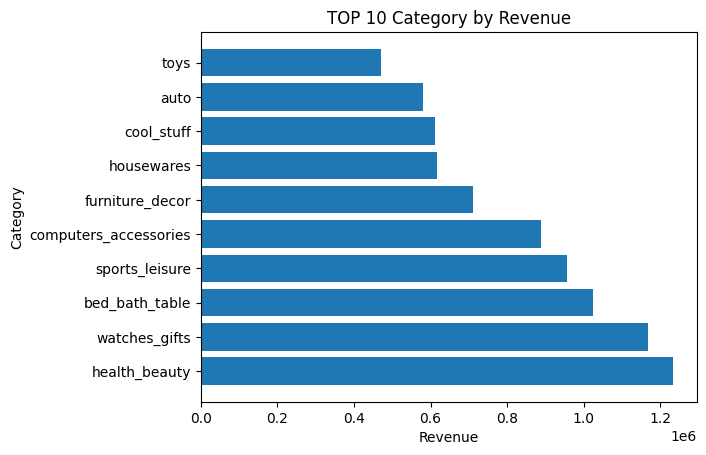

In [69]:
plt.barh(
    top10["category"],
    top10["revenue"]
)

plt.xlabel("Revenue")
plt.ylabel('Category')
plt.title('TOP 10 Category by Revenue')

plt.show()

In [70]:
top10[["category", "items_sold", "revenue", "avg_price"]]

,category,items_sold,revenue,avg_price
0,health_beauty,9465,1233131.72,130.283330
1,watches_gifts,5859,1166176.98,199.040276
2,bed_bath_table,10953,1023434.76,93.438762
3,sports_leisure,8431,954852.55,113.254958
4,computers_accessories,7644,888724.61,116.264339
5,furniture_decor,8160,711927.69,87.246040
6,housewares,6795,615628.69,90.600249
7,cool_stuff,3718,610204.10,164.121598
8,auto,4140,578966.65,139.847017
9,toys,4030,471286.48,116.944536


カテゴリ別売上を見ると、「美容・健康」が約123万で最も高かった。販売数も9,465個と多く、平均単価も約130と比較的高いため、販売数と単価の両方が売上を押し上げていると考えられる。
一方、「時計・ギフト」は販売数が5,859個と「ベッド・バス・テーブル」より少ないものの、平均単価が約199と高く、売上は2位となっている。このことから、高単価の商品が売上に大きく貢献していると考えられる。
「ベッド・バス・テーブル」は販売数が10,953個で最も多いが、平均単価は約93と低めである。そのため、このカテゴリは高単価ではなく、販売数量の多さによって売上を伸ばしていると考えられる。
この結果から、売上が高いカテゴリでも、「販売数が多いタイプ」と「平均単価が高いタイプ」があることが分かった。



4. State Analysis

In [71]:
query = """
SELECT
    c.customer_state AS state,
    SUM(i.price) AS revenue
FROM customers AS c
JOIN orders AS o
    ON c.customer_id = o.customer_id
JOIN order_items AS i
    ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
GROUP BY state
ORDER BY revenue DESC;
"""

state_sales = pd.read_sql_query(query, conn)
state_sales.head(10)

,state,revenue
0,SP,5067633.16
1,RJ,1759651.13
2,MG,1552481.83
3,RS,728897.47
4,PR,666063.51
5,SC,507012.13
6,BA,493584.14
7,DF,296498.41
8,GO,282836.70
9,ES,268643.45


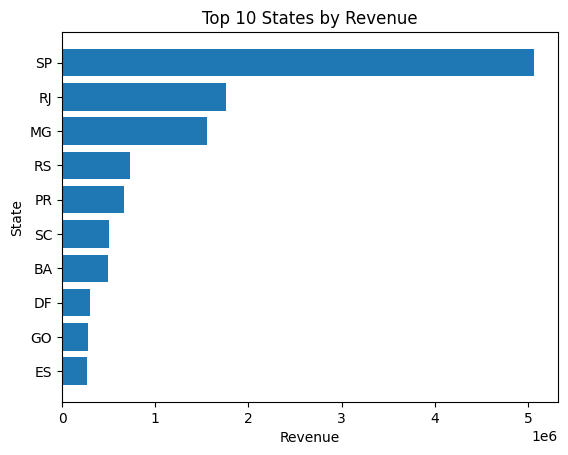

In [72]:
state_sales = pd.read_sql_query(query, conn)
top10_states = state_sales.head(10)
plt.barh(
    top10_states["state"],
    top10_states["revenue"]
)

plt.xlabel("Revenue")
plt.ylabel("State")
plt.title("Top 10 States by Revenue")
plt.gca().invert_yaxis()
plt.show()

In [73]:
query = """
SELECT
    c.customer_state AS state,
    COUNT(DISTINCT o.order_id) AS order_count,
    SUM(i.price) AS revenue,
    SUM(i.price) / COUNT(DISTINCT o.order_id) AS avg_order_value
FROM customers AS c
JOIN orders AS o
    ON c.customer_id = o.customer_id
JOIN order_items AS i
    ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
GROUP BY state
ORDER BY revenue DESC;
"""

state_sales = pd.read_sql_query(query, conn)

state_sales.head(10)

,state,order_count,revenue,avg_order_value
0,SP,40501,5067633.16,125.123655
1,RJ,12350,1759651.13,142.481873
2,MG,11354,1552481.83,136.734352
3,RS,5345,728897.47,136.369966
4,PR,4923,666063.51,135.296264
5,SC,3546,507012.13,142.981424
6,BA,3256,493584.14,151.592181
7,DF,2080,296498.41,142.547312
8,GO,1957,282836.70,144.525652
9,ES,1995,268643.45,134.658371


州別売上は、1注文あたりの金額よりも注文数の多さによる影響が大きい。特にSPは平均注文額が約125と他州より高くない一方、注文数が40,501件と圧倒的に多いため、売上が最も高くなっている。

5. Repeat Customer Analysis

In [74]:
query = """
SELECT
    c.customer_unique_id,
    COUNT(DISTINCT o.order_id) AS order_count
FROM customers AS c
JOIN orders AS o
    ON c.customer_id = o.customer_id
WHERE o.order_status = 'delivered'
GROUP BY c.customer_unique_id
ORDER BY order_count DESC;
"""

customer_orders = pd.read_sql_query(query, conn)

customer_orders.head(10)

,customer_unique_id,order_count
0,8d50f5eadf50201ccdcedfb9e2ac8455,15
1,3e43e6105506432c953e165fb2acf44c,9
2,ca77025e7201e3b30c44b472ff346268,7
3,6469f99c1f9dfae7733b25662e7f1782,7
4,1b6c7548a2a1f9037c1fd3ddfed95f33,7
5,f0e310a6839dce9de1638e0fe5ab282a,6
6,dc813062e0fc23409cd255f7f53c7074,6
7,63cfc61cee11cbe306bff5857d00bfe4,6
8,47c1a3033b8b77b3ab6e109eb4d5fdf3,6
9,12f5d6e1cbf93dafd9dcc19095df0b3d,6


In [75]:
customer_orders['customer_type'] = customer_orders['order_count'].apply(lambda x:'repeat'if x >=2 else 'one-time')

In [76]:
customer_counts = customer_orders['customer_type'].value_counts()
customer_counts

,count
customer_type,
one-time,90557
repeat,2801


In [77]:
repeat_rate = customer_counts['repeat'] / customer_counts.sum()*100

repeat_rate

np.float64(3.0002784978255748)

In [78]:
query_revenue = """
SELECT
    c.customer_unique_id,
    SUM(i.price) AS revenue
FROM customers AS c
JOIN orders AS o
    ON c.customer_id = o.customer_id
JOIN order_items AS i
    ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
GROUP BY c.customer_unique_id
"""

customer_revenue = pd.read_sql_query(query_revenue, conn)
query_revenue = """
SELECT
    c.customer_unique_id,
    SUM(i.price) AS revenue
FROM customers AS c
JOIN orders AS o
    ON c.customer_id = o.customer_id
JOIN order_items AS i
    ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
GROUP BY c.customer_unique_id
"""

customer_revenue = pd.read_sql_query(query_revenue, conn)
customer_revenue.head()


,customer_unique_id,revenue
0,0000366f3b9a7992bf8c76cfdf3221e2,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,18.90
2,0000f46a3911fa3c0805444483337064,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,25.99
4,0004aac84e0df4da2b147fca70cf8255,180.00


In [79]:
customer_analysis = customer_orders.merge(customer_revenue, on='customer_unique_id')
customer_analysis.head()

,customer_unique_id,order_count,customer_type,revenue
0,8d50f5eadf50201ccdcedfb9e2ac8455,15,repeat,714.63
1,3e43e6105506432c953e165fb2acf44c,9,repeat,1000.85
2,ca77025e7201e3b30c44b472ff346268,7,repeat,806.61
3,6469f99c1f9dfae7733b25662e7f1782,7,repeat,664.20
4,1b6c7548a2a1f9037c1fd3ddfed95f33,7,repeat,809.21


In [80]:
revenue_by_type = customer_analysis.groupby("customer_type")["revenue"].sum()
revenue_by_type

,revenue
customer_type,
one-time,12493089.36
repeat,728408.75


In [81]:
revenue_share = revenue_by_type / revenue_by_type.sum()*100

revenue_share

,revenue
customer_type,
one-time,94.490725
repeat,5.509275


In [82]:
customer_share = customer_counts / customer_counts.sum() * 100

customer_share

,count
customer_type,
one-time,96.999722
repeat,3.000278


In [83]:
comparison = pd.DataFrame({
    "customer_share": customer_share,
    "revenue_share": revenue_share
})

comparison

,customer_share,revenue_share
customer_type,,
one-time,96.999722,94.490725
repeat,3.000278,5.509275


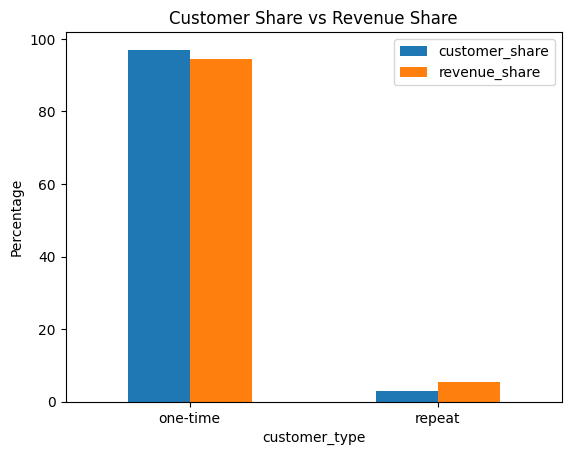

In [84]:
comparison.plot(kind="bar")

plt.ylabel("Percentage")
plt.title("Customer Share vs Revenue Share")
plt.xticks(rotation=0)
plt.show()

リピート顧客は全顧客の約3.0%だが、売上では約5.5%を占めている。
そのため、リピート顧客は人数割合以上に売上へ貢献していると考えられる。

6. Conclusion

## 6. Conclusion

今回の分析では、OlistのECデータを使って、月別売上、商品カテゴリ、州別売上、リピート顧客の4つの視点から売上の特徴を調べた。

月別に見ると、2017年から2018年にかけて注文数と売上は全体的に増えていた。つまり、Olistの取引規模そのものが拡大していたと考えられる。

カテゴリ別では、Health & Beautyの売上が最も高かった。ただし、売上が高くなる理由はカテゴリによって異なっていた。Watches & Giftsは平均単価の高さ、Bed Bath & Tableは販売数の多さが売上につながっていた。

州別では、SPの売上が最も高かった。SPは1注文あたりの金額が特に高いわけではなく、注文数が圧倒的に多かったことが主な理由だった。

リピート顧客は全顧客の約3.0%だったが、売上の約5.5%を占めていた。このことから、リピート顧客は人数は少ないものの、1人あたりでは比較的大きく売上に貢献していると考えられる。

以上から、Olistの売上を伸ばすためには、単に注文数を増やすだけでなく、高単価カテゴリの販売、販売数の多いカテゴリの維持、リピート顧客の増加など、複数の視点から考えることが重要だと考えられる。